# Chapter 65: Economic History, Trade, Technology, and Divergence

This notebook reruns four of the chapter's invented teaching calculations: one machine priced in two regions, coal and imports against a land limit, collective liability for traveling merchants, and railroad social savings. Every number is a constructed teaching number, not historical data; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def adoption_npv(F, w, Ls, pe, E, M, r, n):
    """Machine adoption test: G = w Ls - pe E - M, A_T = (1 - (1 + r)^-T) / r, NPV = G A_T - F,
    threshold wage w* = (F / A_T + pe E + M) / Ls.

    high-wage-cheap-energy-mechanization (chapter 65): F 9,600, Ls 720, E 600, M 480, 8%, 5 years;
    w 11, pe 0.80 gives G 6,960, PV 27,789.26, NPV 18,189.26, w* 4.67; w 4.50, pe 1.80 gives NPV -2,892.25.
    """
    A = (1 - (1 + r) ** (-n)) / r
    G = w * Ls - pe * E - M
    pv = G * A
    return {"annuity": A, "gain": G, "pv": pv, "npv": pv - F, "w_star": (F / A + pe * E + M) / Ls}


def resource_balance(land, needs, reliefs):
    """Land-equivalent balance D = F + B - C - X against capacity L-bar; returns D, relief, slack.

    great-divergence-coal-and-colonies-hypothesis (chapter 65): land 140, needs (98, 62),
    reliefs (14, 11) gives D0 160, D 135, relief 25, slack 5; coal only 146 (deficit 6),
    imports only 149 (deficit 9).
    """
    gross = float(sum(needs))
    relief = float(sum(reliefs))
    demand = gross - relief
    return {"gross": gross, "relief": relief, "demand": demand, "slack": land - demand}


def enforcement_check(gain, p, penalty, fine, k, S):
    """Merchant and community incentives under private remedy and collective responsibility.

    community-responsibility-system (chapter 65):
    gain 18, p 0.15, penalty 40 gives expected cost 6 and private default payoff 12;
    fine 24 gives community default payoff -6; enforcement credible when k 9 <= S 60, not when S 7.
    """
    expected = p * penalty
    credible = k <= S
    return {"expected_cost": expected, "private_payoff": gain - expected, "community_payoff": gain - fine,
            "credible": credible,
            "effective_payoff": (gain - fine) if credible else gain}


def cost_reduction_surplus(c_old, c_new, q_old, q_new):
    """Social savings of a cost cut with linear demand: rectangle (c_old - c_new) q_old plus
    triangle 0.5 (c_old - c_new)(q_new - q_old); fixed-demand version (c_old - c_new) q_new.

    railroad-social-savings (chapter 65):
    0.07, 0.04, 7m, 10m gives 210,000 + 45,000 = 255,000; fixed demand 300,000.
    """
    gap = c_old - c_new
    rect = gap * q_old
    tri = 0.5 * gap * (q_new - q_old)
    return {"gap": gap, "rectangle": rect, "triangle": tri, "total": rect + tri, "fixed": gap * q_new}


plt.rcParams.update(HOUSE_RC)


production = SimpleNamespace(adoption_npv=adoption_npv)


growth = SimpleNamespace(resource_balance=resource_balance)


games = SimpleNamespace(enforcement_check=enforcement_check)


equilibrium = SimpleNamespace(cost_reduction_surplus=cost_reduction_surplus)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'high-wage-cheap-energy-mechanization': {'F': 9600,
                                          'Ls': 720,
                                          'E': 600,
                                          'M': 480,
                                          'T': 5,
                                          'r': 0.08,
                                          'annuity': 3.99271,
                                          'w_H': 11,
                                          'pe_H': 0.8,
                                          'G_H': 6960,
                                          'PV_H': 27789.26,
                                          'NPV_H': 18189.26,
                                          'w_L': 4.5,
                                          'pe_L': 1.8,
                                          'G_L': 1680,
                                          'NPV_L': -2892.25,
                                          'w_star': 4.67},
 'great-divergence-coal-and-colonies-hypothesis': {'land': 140,
                                                   'F': 98,
                                                   'B': 62,
                                                   'C': 14,
                                                   'X': 11,
                                                   'D0': 160,
                                                   'D1': 135,
                                                   'R': 25,
                                                   'slack': 5,
                                                   'D_C': 146,
                                                   'deficit_C': 6,
                                                   'D_X': 149,
                                                   'deficit_X': 9,
                                                   'deficit_0': 20},
 'community-responsibility-system': {'g': 18,
                                     'p': 0.15,
                                     'penalty': 40,
                                     'expected_cost': 6,
                                     'private_payoff': 12,
                                     'f': 24,
                                     'community_payoff': -6,
                                     'k': 9,
                                     'S': 60,
                                     'S_weak': 7},
 'railroad-social-savings': {'cR': 0.04,
                             'QR': 10000000,
                             'cC': 0.07,
                             'QC': 7000000,
                             'gap': 0.03,
                             'rectangle': 210000,
                             'triangle': 45000,
                             'SS': 255000,
                             'SS0': 300000,
                             'overstatement': 45000},
 'constructed': {'high-wage-cheap-energy-mechanization': {'w': [6], 'pe': [1.3]},
                 'great-divergence-coal-and-colonies-hypothesis': {'land': [130, 150]},
                 'community-responsibility-system': {'S': [30]},
                 'railroad-social-savings': {'cC': [0.05, 0.1], 'QC': [5000000]}}}


LABEL = "Constructed teaching numbers, not historical data."


def wage_text(w):
    """4.5 -> '4.50', 11 -> '11'."""
    return num(w, 0) if float(w).is_integer() else num(w)


def machine_picture(w=11, pe=0.80):
    b = BV["high-wage-cheap-energy-mechanization"]
    F, Ls, E, M, r, T = b["F"], b["Ls"], b["E"], b["M"], b["r"], b["T"]
    res = production.adoption_npv(F, w, Ls, pe, E, M, r, T)
    A = res["annuity"]
    fig, ax = new_figure()
    ws = np.linspace(3, 12, 200)
    for p, col in ((0.80, "teal"), (1.30, "navy"), (1.80, "terracotta")):
        npv = [production.adoption_npv(F, x, Ls, p, E, M, r, T)["npv"] for x in ws]
        ax.plot(ws, npv, color=PALETTE[col], linewidth=2.4 if p == pe else 1.3,
                linestyle="solid" if p == pe else "dashed", label=f"energy price {num(p)}")
    ax.legend(loc="upper left", frameon=False)
    hline(ax, 0, None)
    vline(ax, res["w_star"], f"break-even wage {num(res['w_star'])}", col="grey", y_frac=0.12)
    mark(ax, w, res["npv"], f"NPV {money(res['npv'])}", col="ink", dx=-8 if w > 8 else 8, dy=10,
         ha="right" if w > 8 else "left", va="bottom")
    ax.set_xlim(3, 12)
    ax.set_xlabel("Hourly wage ($)")
    ax.set_ylabel("Net present value ($)")
    adopt = res["npv"] > 0
    verdict = "the machine pays" if adopt else "the machine does not pay"
    metrics = {"Annuity factor A_5": num(A, 6), "Annual gain G": money(res["gain"]),
               "Present value": money(res["pv"]), "Net present value": money(res["npv"]),
               "Break-even wage": money(res["w_star"]), "Decision": "Adopt" if adopt else "Do not adopt"}
    steps = [f"A_5 = (1 - 1.08^-5) / 0.08 = {num(A, 6)}",
             f"G = {wage_text(w)} x 720 - {num(pe)} x 600 - 480 = {num(w * Ls)} - {num(pe * E)} - 480 = "
             f"{num(res['gain'])}",
             f"PV = {num(res['gain'])} x {num(A, 6)} = {num(res['pv'])}",
             f"NPV = {num(res['pv'])} - 9,600 = {num(res['npv'])}",
             f"w* = (9,600 / {num(A, 6)} + {num(pe * E)} + 480) / 720 = {num(res['w_star'])}"]
    interp = (f"At a wage of {money(w)} and an energy price of {money(pe)}, the annual gain is "
              f"{wage_text(w)} x 720 - {num(pe)} x 600 - 480 = {num(res['gain'])}, worth {money(res['pv'])} over five years at 8 percent, so NPV = "
              f"{num(res['pv'])} - 9,600 = {num(res['npv'])}: {verdict}. The wage must exceed {money(res['w_star'])} at this energy price. "
              f"{LABEL}")
    alt = (f"Net present value of the same machine against the hourly wage for three energy prices. At wage "
           f"{wage_text(w)} and energy price {num(pe)} the NPV is {num(res['npv'])}; the break-even wage is "
           f"{num(res['w_star'])}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def land_picture(c=14, x=11, land=140):
    b = BV["great-divergence-coal-and-colonies-hypothesis"]
    F, B = b["F"], b["B"]
    res = growth.resource_balance(land, [F, B], [c, x])
    fig, ax = new_figure()
    ax.bar([0], [F], color=PALETTE["olive"], width=0.5, label="food and fiber")
    ax.bar([0], [B], bottom=[F], color=PALETTE["gold"], width=0.5, label="biomass energy")
    top = F + B
    if c:
        ax.bar([1], [c], bottom=[top - c], color=PALETTE["ink"], width=0.5, label="coal relief")
    if x:
        ax.bar([1], [x], bottom=[top - c - x], color=PALETTE["navy"], width=0.5, label="imports relief")
    ax.bar([2], [res["demand"]], color=PALETTE["teal"], width=0.5, label="net local requirement")
    hline(ax, land, f"local land {num(land, 0)}", col="terracotta", style="dashed")
    ax.annotate(num(res["demand"], 0), (2, res["demand"]), xytext=(0, -4), textcoords="offset points",
                ha="center", va="top", fontsize=10.5, color="white")
    ax.set_xticks([0, 1, 2], ["Gross need", "Relief", "Net need"])
    ax.set_ylim(0, 240)
    ax.set_xlim(-0.5, 3.6)
    ax.legend(loc="upper right", frameon=False)
    ax.set_ylabel("Land-equivalent units")
    ax.set_xlabel("Land account")
    slack = res["slack"]
    if slack > 0:
        status, word = f"slack {num(slack, 0)}", "the scale fits"
    elif slack == 0:
        status, word = "exactly at capacity", "the scale just fits"
    else:
        status, word = f"deficit {num(-slack, 0)}", "the scale does not fit"
    metrics = {"Gross requirement F + B": num(res["gross"], 0), "Relief C + X": num(res["relief"], 0),
               "Net requirement D": num(res["demand"], 0), "Local land": num(land, 0),
               "Balance": status.capitalize()}
    steps = [f"F + B = 98 + 62 = {num(res['gross'], 0)}",
             f"R = C + X = {c} + {x} = {num(res['relief'], 0)}",
             f"D = {num(res['gross'], 0)} - {num(res['relief'], 0)} = {num(res['demand'], 0)}",
             f"{num(land, 0)} - {num(res['demand'], 0)} = {num(slack, 0)}, so {status}"]
    cut = (f"With no coal or import relief it stays at 160" if not (c or x) else
           f"Coal relief {c} and imports {x} cut it to 160 - {num(res['relief'], 0)} = {num(res['demand'], 0)}")
    interp = (f"Gross need is 98 + 62 = 160 land units. {cut}, against {num(land, 0)} units of local land: {status}, so {word}. {LABEL}")
    alt = (f"Bars for gross land need 160, relief {num(res['relief'], 0)} and net need {num(res['demand'], 0)}, "
           f"with local land at {num(land, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def liability_picture(regime="community", s=60):
    b = BV["community-responsibility-system"]
    res = games.enforcement_check(b["g"], b["p"], b["penalty"], b["f"], b["k"], s)
    fig, (ax1, ax2) = new_figure(ncols=2)
    if regime == "private":
        payoff = res["private_payoff"]
        names = ["Gain", "Expected cost", "Default payoff"]
        vals = [b["g"], -res["expected_cost"], payoff]
    else:
        payoff = res["community_payoff"]
        names = ["Gain", "Community fine", "Default payoff"]
        vals = [b["g"], -b["f"], payoff]
    cols = [PALETTE["teal"], PALETTE["terracotta"], PALETTE["ink"]]
    ax1.bar(range(3), vals, color=cols, width=0.6)
    for i, v in enumerate(vals):
        ax1.annotate(num(v, 0), (i, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points",
                     ha="center", va="bottom" if v >= 0 else "top", fontsize=10.5)
    ax1.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax1.set_xticks(range(3), names)
    ax1.set_ylim(-32, 28)
    ax1.set_ylabel("Merchant payoff from default")
    ax1.set_xlabel("Merchant")
    ax2.bar([0, 1], [b["k"], s], color=[PALETTE["navy"], PALETTE["gold"]], width=0.6)
    for i, v in enumerate([b["k"], s]):
        ax2.annotate(num(v, 0), (i, v), xytext=(0, 4), textcoords="offset points", ha="center", va="bottom",
                     fontsize=10.5)
    ax2.set_xticks([0, 1], ["Cost to enforce k", "Sanction if refused S"])
    ax2.set_ylim(0, 72)
    ax2.set_ylabel("Cost to the home community")
    ax2.set_xlabel("Home community")
    credible = res["credible"]
    comm = (f"k = 9 {'<' if b['k'] < s else '>'} S = {s}, so the community "
            f"{'enforces' if credible else 'refuses to act'}")
    if regime == "private":
        deter = "Default pays: deterrence fails"
        reading = (f"Under the private remedy the expected cost is 0.15 x 40 = 6, so default pays 18 - 6 = 12. "
                   f"The community stage plays no role in this regime (if asked: {comm}).")
    else:
        if credible:
            deter = "Performance: the fine deters"
            reading = (f"The community fine turns default into 18 - 24 = -6, and {comm}: the threat is "
                       "credible and the merchant performs.")
        else:
            deter = "Deterrence fails: the fine is not credible"
            reading = (f"On paper default pays 18 - 24 = -6, but {comm}. The announced fine loses credibility and "
                       "the deterrence condition fails in practice.")
    metrics = {"Expected private cost": num(res["expected_cost"], 0),
               "Default payoff, private remedy": num(res["private_payoff"], 0),
               "Default payoff if the fine is applied": num(res["community_payoff"], 0),
               "Community enforces": "Yes" if credible else "No", "Outcome": deter}
    steps = ["0.15 x 40 = 6", "Private remedy: 18 - 6 = 12 > 0",
             "Community fine: U_D = 18 - 24 = -6",
             f"Credibility: k = 9 versus S = {s}: {'9 <= ' + str(s) if credible else '9 > ' + str(s)}"]
    interp = f"{reading} {LABEL}"
    alt = (f"Left: merchant's gain 18, the {'expected cost 6' if regime == 'private' else 'community fine 24'} and "
           f"the default payoff {num(payoff, 0)}. Right: community enforcement cost 9 against outside sanction {s}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def rail_picture(cc=0.07, qc=7):
    b = BV["railroad-social-savings"]
    cR, QR = b["cR"], b["QR"] / 1e6
    res = equilibrium.cost_reduction_surplus(cc, cR, qc * 1e6, QR * 1e6)
    fig, ax = new_figure()
    ax.fill_between([0, qc], cR, cc, color=PALETTE["teal"], alpha=0.35, label="retained traffic saving")
    if QR > qc:
        ax.fill([qc, QR, qc], [cc, cR, cR], color=PALETTE["gold"], alpha=0.45, label="induced traffic surplus")
        slope = (cc - cR) / (QR - qc)
        qs = np.linspace(0, 12, 100)
        ax.plot(qs, cc + slope * (qc - qs), color=PALETTE["ink"], linewidth=1.8, label="linear demand")
    else:
        vline(ax, QR, "fixed demand", col="ink", y_frac=0.6, ha="right")
    ax.axhline(cc, color=PALETTE["terracotta"], linewidth=1.6)
    ax.axhline(cR, color=PALETTE["navy"], linewidth=1.6)
    label(ax, 11.8, cc, f"canal and road {num(cc)}", col="terracotta", ha="right", dy=4)
    label(ax, 11.8, cR, f"rail {num(cR)}", col="navy", ha="right", dy=4)
    ax.set_xlim(0, 12)
    ax.set_ylim(0, 0.14)
    ax.legend(loc="upper right" if QR > qc else "upper left", frameon=False)
    ax.set_xlabel("Ton-miles (millions)")
    ax.set_ylabel("Cost per ton-mile ($)")
    total, fixed = res["total"], res["fixed"]
    over = fixed - total
    metrics = {"Cost gap": num(res["gap"]), "Rectangle": num(res["rectangle"], 0), "Triangle": num(res["triangle"], 0),
               "Social savings": num(total, 0), "Fixed-demand estimate": num(fixed, 0),
               "Overstatement": num(over, 0)}
    steps = [f"c_C - c_R = {num(cc)} - 0.04 = {num(res['gap'])}",
             f"Rectangle = {num(res['gap'])} x {num(qc * 1e6, 0)} = {num(res['rectangle'], 0)}",
             f"Triangle = 0.5 x {num(res['gap'])} x (10,000,000 - {num(qc * 1e6, 0)}) = {num(res['triangle'], 0)}",
             f"SS = {num(res['rectangle'], 0)} + {num(res['triangle'], 0)} = {num(total, 0)}",
             f"SS_0 = {num(res['gap'])} x 10,000,000 = {num(fixed, 0)}; overstatement {num(over, 0)}"]
    if over > 0:
        tail = f"Holding all rail traffic fixed overstates the savings by {num(over, 0)}."
    else:
        tail = "All traffic would move anyway, so the fixed-demand estimate is exact here."
    interp = (f"With an alternative cost of {num(cc)} and {num(qc, 0)} million ton-miles under it, social savings are "
              f"{num(res['rectangle'], 0)} + {num(res['triangle'], 0)} = {num(total, 0)}. {tail} {LABEL}")
    alt = (f"Transport cost lines at {num(cc)} and 0.04 with the saving on {num(qc, 0)} million retained ton-miles "
           f"shaded{', plus the induced-traffic triangle up to 10 million' if QR > qc else ''}. "
           f"Social savings {num(total, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. High-wage, cheap-energy mechanization: same machine, different regions

A machine costs \$9,600, saves 720 hours a year, uses 600 energy units and \$480 of maintenance, lasts five years and is discounted at 8 percent.

$$A_5=\frac{1-(1.08)^{-5}}{0.08}\approx3.992710, \qquad G_H=11(720)-0.80(600)-480=6{,}960$$

$$w^*=\frac{9{,}600/3.992710+0.80(600)+480}{720}\approx4.67$$

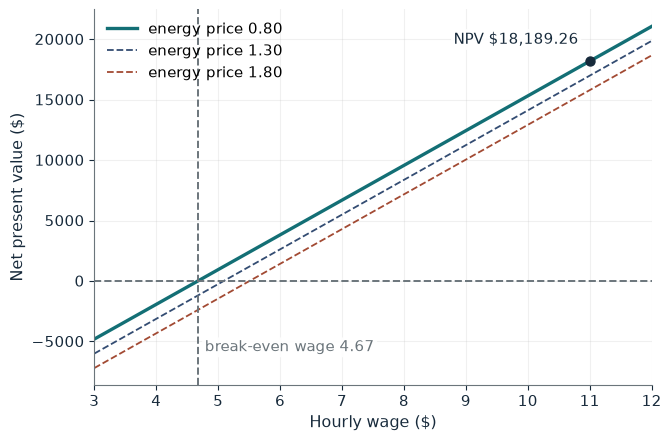

Annuity factor A_5  3.992710
Annual gain G       $6,960.00
Present value       $27,789.26
Net present value   $18,189.26
Break-even wage     $4.67
Decision            Adopt

Worked steps:
  1. A_5 = (1 - 1.08^-5) / 0.08 = 3.992710
  2. G = 11 x 720 - 0.80 x 600 - 480 = 7,920.00 - 480.00 - 480 = 6,960.00
  3. PV = 6,960.00 x 3.992710 = 27,789.26
  4. NPV = 27,789.26 - 9,600 = 18,189.26
  5. w* = (9,600 / 3.992710 + 480.00 + 480) / 720 = 4.67

At a wage of $11.00 and an energy price of $0.80, the annual gain is 11 x 720 - 0.80 x 600 - 480 = 6,960.00, worth $27,789.26 over five years at 8 percent, so NPV = 27,789.26 - 9,600 = 18,189.26: the machine pays. The wage must exceed $4.67 at this energy price. Constructed teaching numbers, not historical data.


In [2]:
show(machine_picture(w=11, pe=0.80))

Change one input, `w`, and hold the others at the book's values:

In [3]:
sweep(machine_picture, 'w', [4.5, 6, 11], {'pe': 1.8}, ['Annual gain G', 'Net present value', 'Break-even wage'])

w | Annual gain G | Net present value | Break-even wage
4.5 | $1,680.00 | -$2,892.25 | $5.51
6 | $2,760.00 | $1,419.88 | $5.51
11 | $6,360.00 | $15,793.64 | $5.51


In region H the NPV is \$18,189.26. At region L's prices (wage \$4.50, energy \$1.80) the gain falls to \$1,680 and NPV to -\$2,892.25: the same design pays in one place and not the other.

## 2. Coal plus colonies relax the land limit

Local land is 140 units; food and fiber need 98 and biomass energy 62.

$$D_0=98+62=160, \qquad D_1=98+62-14-11=135$$

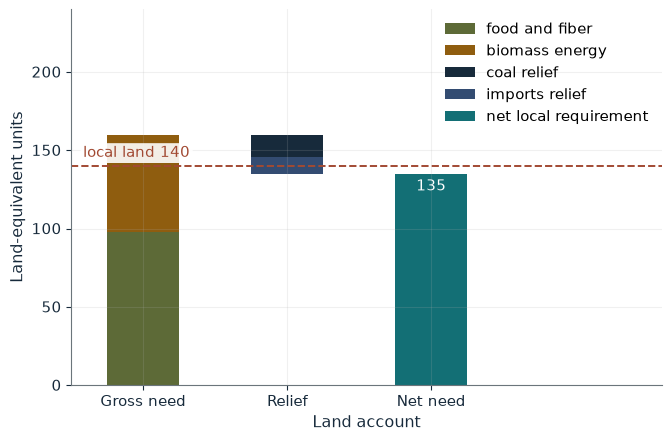

Gross requirement F + B  160
Relief C + X             25
Net requirement D        135
Local land               140
Balance                  Slack 5

Worked steps:
  1. F + B = 98 + 62 = 160
  2. R = C + X = 14 + 11 = 25
  3. D = 160 - 25 = 135
  4. 140 - 135 = 5, so slack 5

Gross need is 98 + 62 = 160 land units. Coal relief 14 and imports 11 cut it to 160 - 25 = 135, against 140 units of local land: slack 5, so the scale fits. Constructed teaching numbers, not historical data.


In [4]:
show(land_picture(c=14, x=11, land=140))

Change one input, `c`, and hold the others at the book's values:

In [5]:
sweep(land_picture, 'c', [0, 14], {'x': 0, 'land': 140}, ['Net requirement D', 'Balance'])

c | Net requirement D | Balance
0 | 160 | Deficit 20
14 | 146 | Deficit 6


Together, coal (14) and imports (11) leave slack 5. Coal alone leaves a deficit of 6 and imports alone a deficit of 9, so neither is enough by itself under these invented quantities.

## 3. Community responsibility: holding the whole community liable

A merchant gains 18 by defaulting. The private remedy recovers with probability 0.15 and penalty 40; the home community can fine 24 at an enforcement cost of 9.

$$0.15(40)=6, \qquad U_D=18-24=-6, \qquad 9<60$$

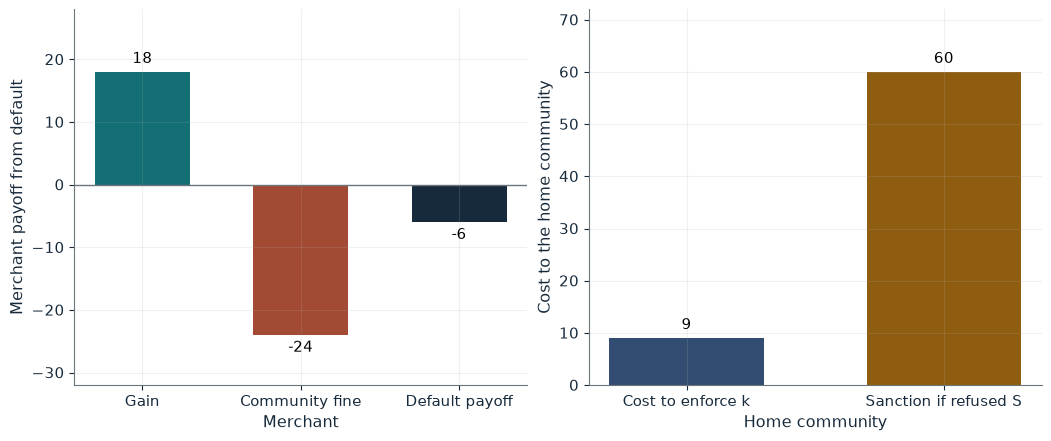

Expected private cost                  6
Default payoff, private remedy         12
Default payoff if the fine is applied  -6
Community enforces                     Yes
Outcome                                Performance: the fine deters

Worked steps:
  1. 0.15 x 40 = 6
  2. Private remedy: 18 - 6 = 12 > 0
  3. Community fine: U_D = 18 - 24 = -6
  4. Credibility: k = 9 versus S = 60: 9 <= 60

The community fine turns default into 18 - 24 = -6, and k = 9 < S = 60, so the community enforces: the threat is credible and the merchant performs. Constructed teaching numbers, not historical data.


In [6]:
show(liability_picture(regime='community', s=60))

Change one input, `s`, and hold the others at the book's values:

In [7]:
sweep(liability_picture, 's', [7, 30, 60], {'regime': 'community'}, ['Community enforces', 'Outcome'])

s | Community enforces | Outcome
7 | No | Deterrence fails: the fine is not credible
30 | Yes | Performance: the fine deters
60 | Yes | Performance: the fine deters


Under the private remedy default pays 12. Collective liability makes it -6, but only while enforcing (9) costs less than the outside sanction; at S = 7 the fine is not credible.

## 4. Railroad social savings: measuring what railroads saved

Rail costs 0.04 per ton-mile and carries 10 million ton-miles; the alternative costs 0.07 and would carry 7 million.

$$\frac{1}{2}(0.03)(10{,}000{,}000-7{,}000{,}000)=45{,}000, \qquad SS_0=0.03(10{,}000{,}000)=300{,}000$$

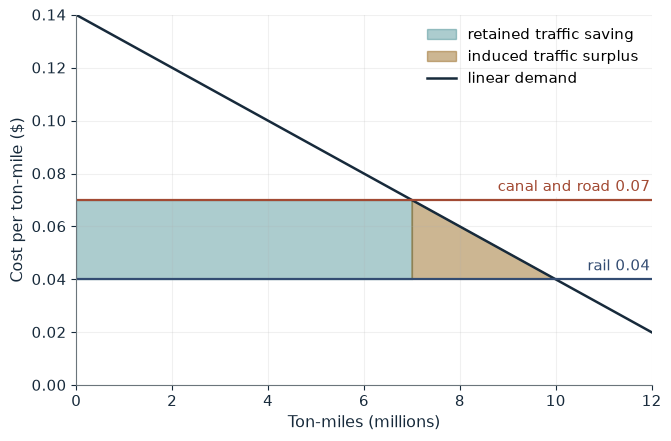

Cost gap               0.03
Rectangle              210,000
Triangle               45,000
Social savings         255,000
Fixed-demand estimate  300,000
Overstatement          45,000

Worked steps:
  1. c_C - c_R = 0.07 - 0.04 = 0.03
  2. Rectangle = 0.03 x 7,000,000 = 210,000
  3. Triangle = 0.5 x 0.03 x (10,000,000 - 7,000,000) = 45,000
  4. SS = 210,000 + 45,000 = 255,000
  5. SS_0 = 0.03 x 10,000,000 = 300,000; overstatement 45,000

With an alternative cost of 0.07 and 7 million ton-miles under it, social savings are 210,000 + 45,000 = 255,000. Holding all rail traffic fixed overstates the savings by 45,000. Constructed teaching numbers, not historical data.


In [8]:
show(rail_picture(cc=0.07, qc=7))

Change one input, `qc`, and hold the others at the book's values:

In [9]:
sweep(rail_picture, 'qc', [5, 7, 10], {'cc': 0.07}, ['Rectangle', 'Triangle', 'Social savings', 'Overstatement'])

qc | Rectangle | Triangle | Social savings | Overstatement
5 | 150,000 | 75,000 | 225,000 | 75,000
7 | 210,000 | 45,000 | 255,000 | 45,000
10 | 300,000 | 0 | 300,000 | 0


Social savings are 210,000 + 45,000 = 255,000. Holding all rail traffic fixed gives 300,000, an overstatement of 45,000; with no traffic loss (Q_C = 10 million) the two agree.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

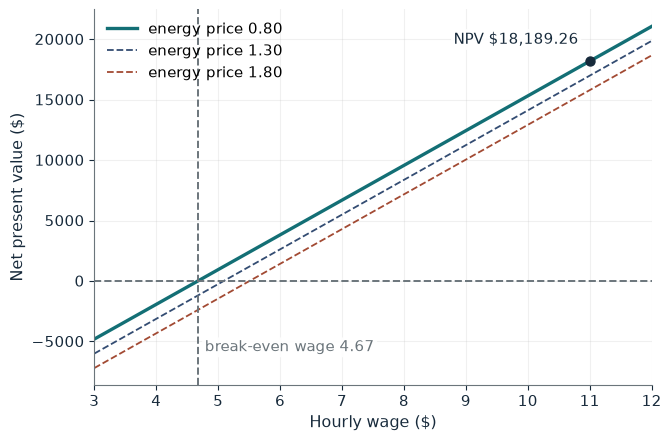

Annuity factor A_5  3.992710
Annual gain G       $6,960.00
Present value       $27,789.26
Net present value   $18,189.26
Break-even wage     $4.67
Decision            Adopt

Worked steps:
  1. A_5 = (1 - 1.08^-5) / 0.08 = 3.992710
  2. G = 11 x 720 - 0.80 x 600 - 480 = 7,920.00 - 480.00 - 480 = 6,960.00
  3. PV = 6,960.00 x 3.992710 = 27,789.26
  4. NPV = 27,789.26 - 9,600 = 18,189.26
  5. w* = (9,600 / 3.992710 + 480.00 + 480) / 720 = 4.67

At a wage of $11.00 and an energy price of $0.80, the annual gain is 11 x 720 - 0.80 x 600 - 480 = 6,960.00, worth $27,789.26 over five years at 8 percent, so NPV = 27,789.26 - 9,600 = 18,189.26: the machine pays. The wage must exceed $4.67 at this energy price. Constructed teaching numbers, not historical data.


In [10]:
show(machine_picture(w=11, pe=0.80))

## Practice

**1.** At a wage of \$6 and energy price \$1.30, does the machine pay?

<details><summary>Answer</summary>

G = 6 x 720 - 1.30 x 600 - 480 = 4,320 - 780 - 480 = 3,060; NPV = 3,060 x 3.992710 - 9,600 = 2,617.69 > 0, so it pays.

</details>

**2.** With imports only and 150 units of land, what is the balance?

<details><summary>Answer</summary>

160 - 11 = 149; 150 - 149 = 1 unit of slack.

</details>

**3.** With an alternative cost of 0.10 and 5 million ton-miles retained, what are social savings?

<details><summary>Answer</summary>

Gap 0.06; 0.06 x 5,000,000 = 300,000; 0.5 x 0.06 x 5,000,000 = 150,000; SS = 450,000 against 600,000 with fixed demand.

</details>